# Predicting Top-Tier Economies from World Bank Indicators

**Dataset:** [World Bank Databank](https://databank.worldbank.org/)
GDP and population by country, 2000-2023, merged with a country
region/continent lookup (Credit and Economic Data category).

## Motivation
The World Bank tracks GDP and population for nearly every country in the
world every year. This project asks: **using only a country's population
size and how fast its population and economy are growing without
looking at its GDP level directly can we predict whether it belongs to
the top 25% of economies (by GDP per capita) in a given year? And does
the model make that call fairly across different world regions?**

This notebook follows the **CRISP-DM** process:
1. Exploratory Data Analysis
2. Data cleaning & merging
3. Model training & evaluation
4. Prediction on a new scenario


## 1. Imports & Data Load

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

gdp = pd.read_csv("data/gdp.csv").rename(columns={"Value": "GDP"})
pop = pd.read_csv("data/population.csv").rename(columns={"Value": "Population"})

country_codes = pd.read_csv(
    "data/country-codes.csv", encoding="utf-8", on_bad_lines="skip",
    keep_default_na=False, na_values=[""]
)

print("GDP records:", gdp.shape)
print("Population records:", pop.shape)
print("Country reference records:", country_codes.shape)
gdp.head()


GDP records: (13979, 4)
Population records: (17195, 4)
Country reference records: (249, 56)


,Country Name,Country Code,Year,GDP
0,Afghanistan,AFG,2000,3.521418e+09
1,Afghanistan,AFG,2001,2.813572e+09
2,Afghanistan,AFG,2002,3.825701e+09
3,Afghanistan,AFG,2003,4.520947e+09
4,Afghanistan,AFG,2004,5.224897e+09


## 2. Merge the Three Sources

In [3]:
country_codes = country_codes[
    ["ISO3166-1-Alpha-3", "Region Name", "Sub-region Name", "Continent"]
].rename(columns={"ISO3166-1-Alpha-3": "Country Code"})
country_codes = country_codes.dropna(subset=["Country Code"])

df = gdp.merge(pop[["Country Code", "Year", "Population"]], on=["Country Code", "Year"], how="inner")
print("After merging GDP + Population:", df.shape)

df = df.merge(country_codes, on="Country Code", how="inner")
print("After keeping only real countries:", df.shape)

df = df[df["Year"] >= 2000].copy()
df["GDP_per_capita"] = df["GDP"] / df["Population"]
print("Final range:", df["Year"].min(), "-", df["Year"].max())
print(df["Country Code"].nunique(), "countries")
df.head()


After merging GDP + Population: (13979, 5)
After keeping only real countries: (11113, 8)
Final range: 2000 - 2023
212 countries


,Country Name,Country Code,Year,GDP,Population,Region Name,Sub-region Name,Continent,GDP_per_capita
0,Afghanistan,AFG,2000,3.521418e+09,20130327,Asia,Southern Asia,AS,174.930991
1,Afghanistan,AFG,2001,2.813572e+09,20284307,Asia,Southern Asia,AS,138.706822
2,Afghanistan,AFG,2002,3.825701e+09,21378117,Asia,Southern Asia,AS,178.954088
3,Afghanistan,AFG,2003,4.520947e+09,22733049,Asia,Southern Asia,AS,198.871116
4,Afghanistan,AFG,2004,5.224897e+09,23560654,Asia,Southern Asia,AS,221.763654


## 3. Exploratory Data Analysis (EDA)

In [3]:
df["Continent"].value_counts()


Continent
AF    1268
AS    1117
EU    1097
NA     730
OC     466
SA     279
Name: count, dtype: int64

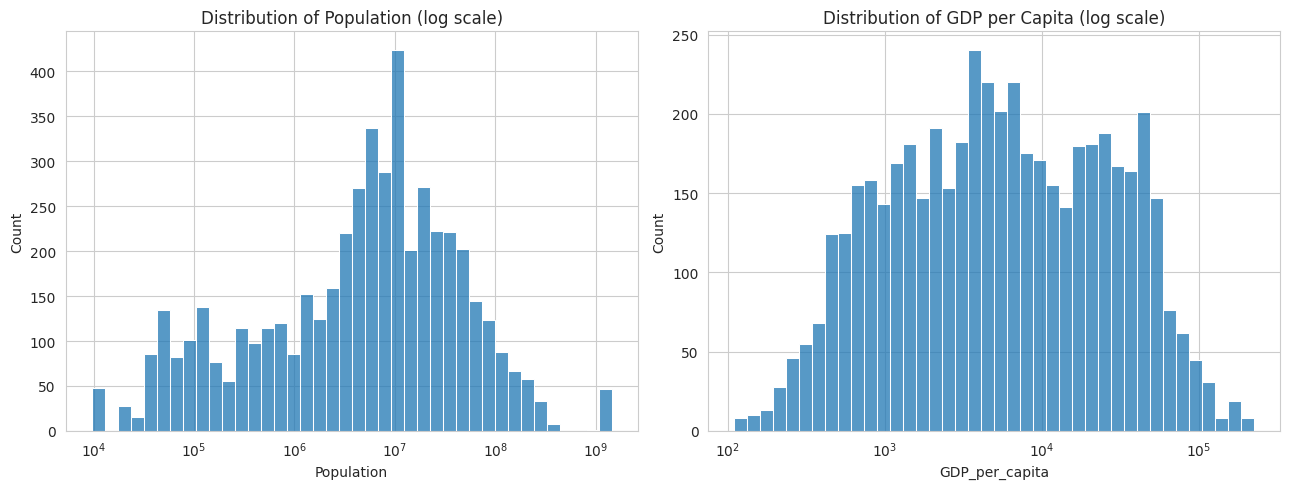

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(df["Population"], bins=40, ax=axes[0], log_scale=True)
axes[0].set_title("Distribution of Population (log scale)")

sns.histplot(df["GDP_per_capita"], bins=40, ax=axes[1], log_scale=True)
axes[1].set_title("Distribution of GDP per Capita (log scale)")

plt.tight_layout()
plt.savefig("images/distributions.png", dpi=120)
plt.show()


**Observation:** both population and GDP per capita are extremely
right-skewed on a linear scale (a small number of huge/wealthy countries
dominate) the log scale above makes the shape much more workable.

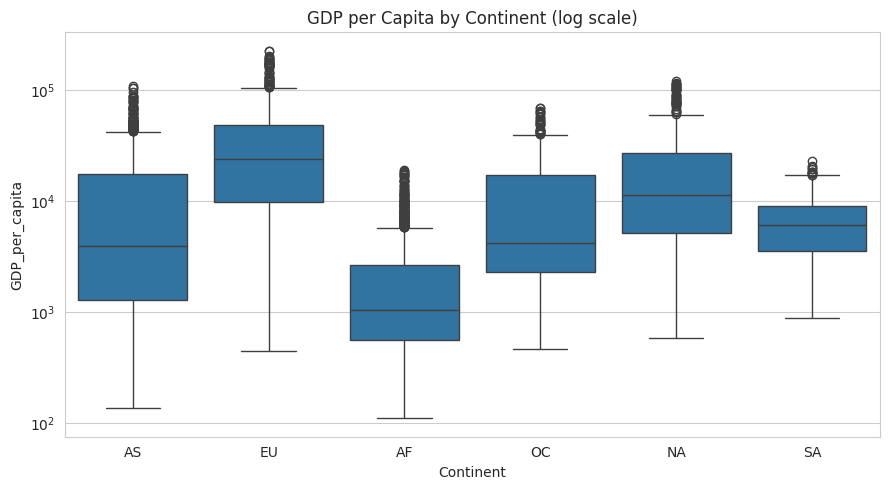

In [5]:
plt.figure(figsize=(9, 5))
sns.boxplot(x="Continent", y="GDP_per_capita", data=df)
plt.yscale("log")
plt.title("GDP per Capita by Continent (log scale)")
plt.tight_layout()
plt.savefig("images/gdp_by_continent.png", dpi=120)
plt.show()


## 4. Data Cleaning & Feature Engineering

Because inflation makes a *fixed dollar* income threshold misleading
across 24 years, we define **"top-tier economy"** relative to each year:
a country-year is top-tier if its GDP per capita is in the **top 25%
globally that year**. This keeps the definition fair across the whole
time range instead of penalizing earlier years for inflation.

We also engineer two **growth-rate features** per country (year-over-year
% change in GDP and population) these capture economic dynamics without
directly leaking the GDP level itself.

In [4]:
df = df.sort_values(["Country Code", "Year"])
df["GDP_growth_pct"] = df.groupby("Country Code")["GDP"].pct_change() * 100
df["Population_growth_pct"] = df.groupby("Country Code")["Population"].pct_change() * 100

df["gdp_pc_percentile"] = df.groupby("Year")["GDP_per_capita"].rank(pct=True)
df["top_tier"] = (df["gdp_pc_percentile"] >= 0.75).astype(int)

df["top_tier"].value_counts(normalize=True)


top_tier
0    0.746823
1    0.253177
Name: proportion, dtype: float64

In [7]:
df_model = df.dropna(subset=["GDP_growth_pct", "Population_growth_pct"]).copy()
print("Rows after dropping first-year-per-country (no growth rate yet):", len(df_model))

feature_cols = ["Population", "GDP_growth_pct", "Population_growth_pct", "Continent", "Year"]
df_model = df_model[feature_cols + ["top_tier", "Country Name"]].copy()

le_continent = LabelEncoder()
df_model["Continent"] = le_continent.fit_transform(df_model["Continent"])

df_model.head()


Rows after dropping first-year-per-country (no growth rate yet): 4745


,Population,GDP_growth_pct,Population_growth_pct,Continent,Year,top_tier,Country Name
370,91439,1.227918,0.939418,3,2001,1,Aruba
371,92074,3.447829,0.694452,3,2002,1,Aruba
372,93128,4.193411,1.144731,3,2003,1,Aruba
373,95138,10.308585,2.158320,3,2004,1,Aruba
374,97635,4.664944,2.624608,3,2005,1,Aruba


## 5. Train the Model

We use a **Random Forest Classifier**, holding out 25% of the data for
testing. Note the features deliberately **exclude GDP and GDP per
capita** we're testing whether population dynamics and region alone
carry a useful signal.

In [8]:
X = df_model[["Population", "GDP_growth_pct", "Population_growth_pct", "Continent", "Year"]]
y = df_model["top_tier"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]


## 6. Evaluate the Model

In [9]:
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_proba)

print(f"Accuracy:  {acc:.3f}")
print(f"Precision: {prec:.3f}")
print(f"Recall:    {rec:.3f}")
print(f"F1 score:  {f1:.3f}")
print(f"ROC AUC:   {auc:.3f}")
print()
print(classification_report(y_test, y_pred, target_names=["Not top-tier", "Top-tier"], zero_division=0))


Accuracy:  0.920
Precision: 0.932
Recall:    0.737
F1 score:  0.823
ROC AUC:   0.977

              precision    recall  f1-score   support

Not top-tier       0.92      0.98      0.95       887
    Top-tier       0.93      0.74      0.82       300

    accuracy                           0.92      1187
   macro avg       0.92      0.86      0.89      1187
weighted avg       0.92      0.92      0.92      1187



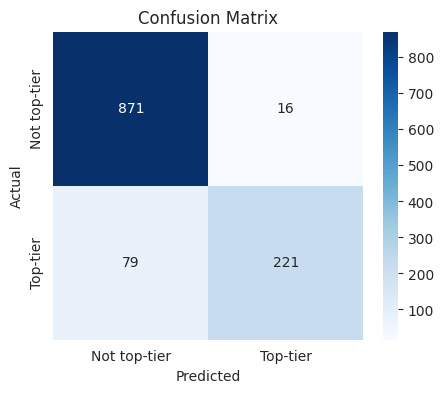

In [10]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not top-tier", "Top-tier"],
            yticklabels=["Not top-tier", "Top-tier"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.savefig("images/confusion_matrix.png", dpi=120)
plt.show()


**What these measures mean, in plain language:**
- **Accuracy** - the overall percentage of country-years correctly
  classified as top-tier or not. Since 25% of records are top-tier by
  design, a lazy model that always guesses "not top-tier" would score
  75% accuracy so accuracy alone isn't very informative here.
- **Precision** (for "Top-tier") - of the country-years the model called
  top-tier, what fraction actually were.
- **Recall** (for "Top-tier") - of the country-years that actually were
  top-tier, what fraction the model caught.
- **F1 score** - the balance between precision and recall.
- **ROC AUC** - how well the model ranks a truly top-tier country-year
  above a typical one, across all thresholds.

### Feature importance

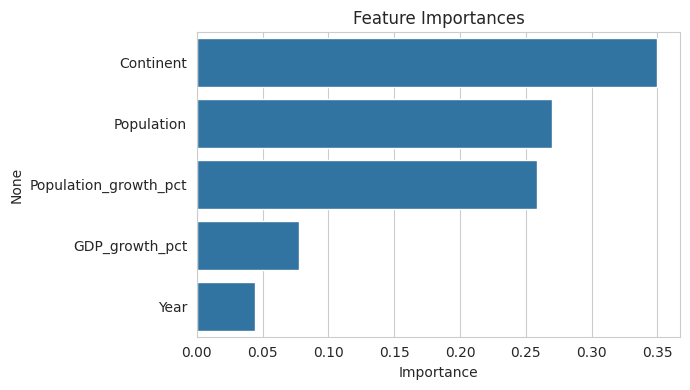

Continent                0.349784
Population               0.269814
Population_growth_pct    0.258469
GDP_growth_pct           0.077935
Year                     0.043997
dtype: float64

In [11]:
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(7, 4))
sns.barplot(x=importances.values, y=importances.index)
plt.title("Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("images/feature_importance.png", dpi=120)
plt.show()

importances


## 7. Fairness Check: Error Rates by Continent

A model like this could plausibly feed into how an analyst or investor
screens countries. We check whether it's equally accurate across world
regions, or whether some continents get systematically mis-classified.

- **False positive rate (FPR):** among country-years that were *not*
  actually top-tier, what fraction did the model wrongly call top-tier?
- **False negative rate (FNR):** among country-years that *were* actually
  top-tier, what fraction did the model wrongly miss?

**In plain language:** a high false negative rate for a continent means
genuinely wealthy countries from that region are more likely to be
overlooked by this model which matters if population/growth dynamics
alone are being used as an (imperfect) stand-in for economic screening.

In [12]:
continent_names = dict(zip(le_continent.transform(le_continent.classes_), le_continent.classes_))

def group_error_rates(test_index, y_true, y_pred, group_col, original_df, name_map=None):
    results = []
    groups = original_df.loc[test_index, group_col]
    for g in sorted(groups.unique()):
        mask = (groups == g).values
        yt = y_true[mask]
        yp = y_pred[mask]
        neg_mask = yt == 0
        fpr = (yp[neg_mask] == 1).mean() if neg_mask.sum() > 0 else np.nan
        pos_mask = yt == 1
        fnr = (yp[pos_mask] == 0).mean() if pos_mask.sum() > 0 else np.nan
        label = name_map[g] if name_map else g
        results.append({"continent": label, "n": mask.sum(), "n_top_tier": pos_mask.sum(), "FPR": fpr, "FNR": fnr})
    return pd.DataFrame(results)

continent_rates = group_error_rates(
    X_test.index, y_test.values, y_pred, "Continent", df_model, continent_names
)
display(continent_rates)


,continent,n,n_top_tier,FPR,FNR
0,AF,319,0,0.000000,NaN
1,AS,269,71,0.020202,0.492958
2,EU,260,153,0.112150,0.058824
3,NA,149,55,0.000000,0.327273
4,OC,105,21,0.000000,0.809524
5,SA,85,0,0.000000,NaN


**What this run found:**

| Continent | n (test) | Actually top-tier | False Positive Rate | False Negative Rate |
|---|---|---|---|---|
| Africa (AF) | 319 | 0 | 0.0% | -- (no true positives in this split) |
| Asia (AS) | 269 | 71 | 2.0% | **49.3%** |
| Europe (EU) | 260 | 153 | 11.2% | **5.9%** |
| North America (NA) | 149 | 55 | 0.0% | 32.7% |
| Oceania (OC) | 105 | 21 | 0.0% | **80.9%** |
| South America (SA) | 85 | 0 | 0.0% | -- (no true positives in this split) |

This is a striking gap. **Europe's genuinely top-tier economies are
almost always correctly identified (94% recall / 5.9% FNR)**, while
**Oceania's top-tier economies are missed 81% of the time**, and Asia's
are missed roughly **half** the time. Since "Continent" was the single
most important feature the model used (Section 6), the model appears to
have learned something close to *"if it's Europe, it's probably
top-tier"* as a strong shortcut, which works well for Europe but causes
wealthy countries in Asia, Oceania, and North America to be
under-recognized even when their actual population/growth profile looks
similar.

This is exactly the kind of finding worth surfacing plainly: a model that
looks highly accurate overall (92%) can still encode a strong regional
shortcut that quietly penalizes non-European high performers.

## 8. Predicting on a New Scenario

Let's imagine a new, hypothetical country-year and see what the model
predicts.

**Scenario:** A country in Asia in 2023 with a population of 15 million,
GDP growing at 6% that year, and population growing at 1.2%.

In [13]:
new_country = pd.DataFrame([{
    "Population": 15_000_000,
    "GDP_growth_pct": 6.0,
    "Population_growth_pct": 1.2,
    "Continent": "AS",
    "Year": 2023,
}])

new_country_encoded = new_country.copy()
new_country_encoded["Continent"] = le_continent.transform(new_country_encoded["Continent"])
new_country_encoded = new_country_encoded[X.columns]

pred = model.predict(new_country_encoded)[0]
proba = model.predict_proba(new_country_encoded)[0][1]

print(f"Predicted class: {'Top-tier economy' if pred == 1 else 'Not top-tier'}")
print(f"Model confidence (probability of top-tier): {proba:.2%}")


Predicted class: Not top-tier
Model confidence (probability of top-tier): 7.44%


**What this prediction means:** the model compared this hypothetical
country's population size, growth rate, region, and year against the
historical patterns of 200 real countries over 24 years. It never saw
this country's actual GDP only demographic dynamics and region. The
output is a probability, not a certainty: it reflects how similar this
profile is to country-years that historically *were* or *weren't* in the
top economic quartile globally. A fast-growing, mid-sized Asian economy
in 2023 resembles a mix of both outcomes historically, so treat this as
"countries with this profile have tended to land here" not a forecast
for any real country.